# Assignment 7

## Perceptron Learning Algorithm

### Dataset: Iris (Setosa and Versicolor)

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score


In [ ]:

iris = load_iris()

X = iris.data[:100, 2:4]
y = iris.target[:100]

print("Dataset shape:", X.shape)
print("Classes:", np.unique(y))
print("Features: Petal Length and Petal Width")
print("Class names:", iris.target_names[:2])


Dataset shape: (100, 2)
Classes: [0 1]
Features: Petal Length and Petal Width
Class names: ['setosa' 'versicolor']


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 80
Testing samples: 20


In [ ]:

model = Perceptron(
    eta0=0.1,
    max_iter=1000,
    tol=1e-3,
    random_state=42,
    shuffle=False
)

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred) * 100, "%")
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred) * 100, "%")
print("Number of epochs:", model.n_iter_)
print("Weights:", model.coef_)
print("Bias:", model.intercept_)


Training Accuracy: 100.0 %
Testing Accuracy: 100.0 %
Number of epochs: 7
Weights: [[0.12 0.14]]
Bias: [-0.4]



## Part (c): Implementation of Perceptron Learning Algorithm From Scratch


In [ ]:

def perceptron_scratch(X, y, learning_rate=0.1, max_epochs=1000):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    epoch_errors = []
    misclassified_per_epoch = []

    for epoch in range(max_epochs):
        errors = 0

        for i in range(n_samples):
            linear_output = np.dot(X[i], weights) + bias
            prediction = 1 if linear_output >= 0 else 0

            if prediction != y[i]:
                update = learning_rate * (y[i] - prediction)
                weights += update * X[i]
                bias += update
                errors += 1

        epoch_errors.append(errors)
        misclassified_per_epoch.append(errors)

        if errors == 0:
            break

    return weights, bias, epoch + 1, epoch_errors, misclassified_per_epoch


In [ ]:

weights, bias, epochs, epoch_errors, misclassified = perceptron_scratch(
    X_train, y_train,
    learning_rate=0.1,
    max_epochs=1000
)

print("Weights:", weights)
print("Bias:", bias)
print("Epochs required:", epochs)
print("Misclassified samples per epoch:", misclassified)


Weights: [0.12 0.14]
Bias: -0.4
Epochs required: 2
Misclassified samples per epoch: [10, 0]


In [ ]:

def predict_scratch(X, weights, bias):
    return (np.dot(X, weights) + bias >= 0).astype(int)

y_train_pred_scratch = predict_scratch(X_train, weights, bias)
y_test_pred_scratch = predict_scratch(X_test, weights, bias)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_scratch) * 100, "%")

print("Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_scratch) * 100, "%")


Training Accuracy: 100.0 %
Testing Accuracy: 100.0 %


## Part (e) — Visualize the Decision Boundary.

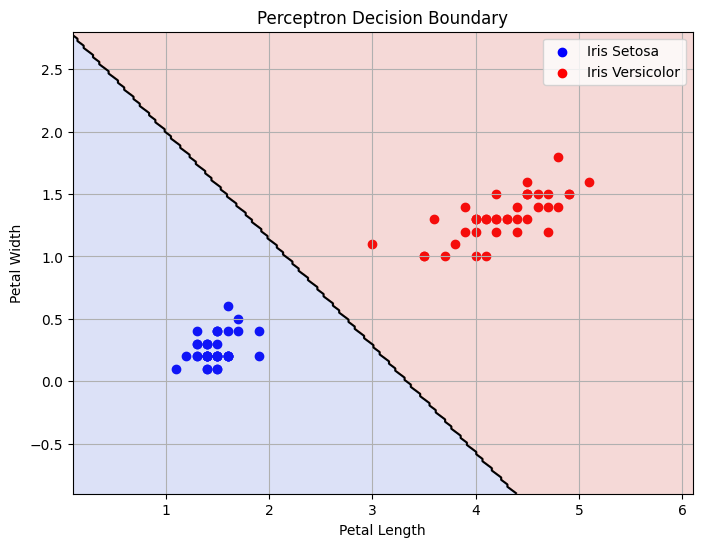

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    color="blue",
    label="Iris Setosa"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    color="red",
    label="Iris Versicolor"
)

x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = predict_scratch(grid, weights, bias).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.2, cmap="coolwarm")
plt.contour(xx, yy, Z, levels=[0.5], colors="black")

plt.title("Perceptron Decision Boundary")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend()
plt.grid(True)
plt.show()


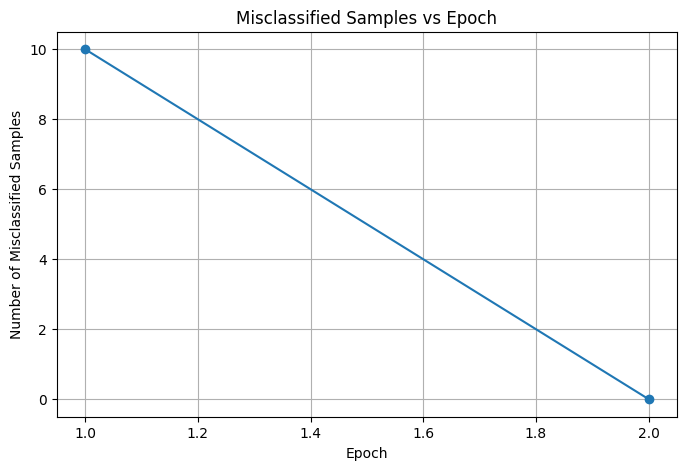

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(misclassified) + 1),
    misclassified,
    marker="o"
)

plt.title("Misclassified Samples vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Number of Misclassified Samples")
plt.grid(True)
plt.show()


In [ ]:

learning_rates = [0.01, 0.1, 1.0]
results = []

for lr in learning_rates:
    w, b, n_epochs, errors, _ = perceptron_scratch(
        X_train,
        y_train,
        learning_rate=lr,
        max_epochs=1000
    )

    results.append({
        "Learning Rate": lr,
        "Epochs Required": n_epochs,
        "Training Accuracy (%)": accuracy_score(
            y_train, predict_scratch(X_train, w, b)
        ) * 100,
        "Testing Accuracy (%)": accuracy_score(
            y_test, predict_scratch(X_test, w, b)
        ) * 100
    })

results_df = pd.DataFrame(results)
print(results_df)


   Learning Rate  Epochs Required  Training Accuracy (%)  Testing Accuracy (%)
0           0.01                2                  100.0                 100.0
1           0.10                2                  100.0                 100.0
2           1.00                2                  100.0                 100.0


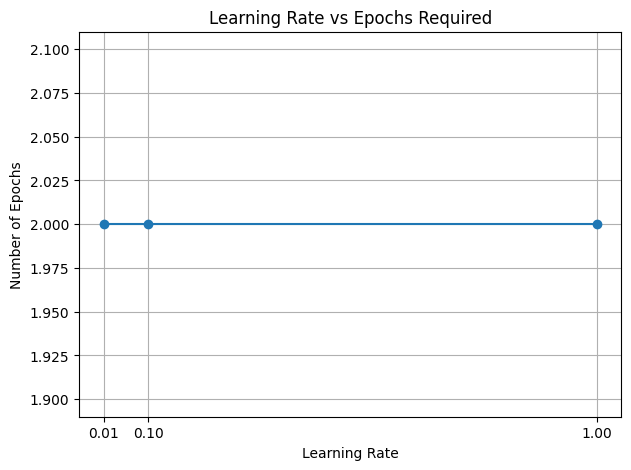

In [ ]:

plt.figure(figsize=(7, 5))

plt.plot(
    results_df["Learning Rate"],
    results_df["Epochs Required"],
    marker="o"
)

plt.title("Learning Rate vs Epochs Required")
plt.xlabel("Learning Rate")
plt.ylabel("Number of Epochs")
plt.xticks(learning_rates)
plt.grid(True)
plt.show()


In [ ]:

def perceptron_with_shuffle(X, y, learning_rate=0.1, max_epochs=1000):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0
    epoch_errors = []

    for epoch in range(max_epochs):
        indices = np.random.permutation(n_samples)
        errors = 0

        for i in indices:
            linear_output = np.dot(X[i], weights) + bias
            prediction = 1 if linear_output >= 0 else 0

            if prediction != y[i]:
                update = learning_rate * (y[i] - prediction)
                weights += update * X[i]
                bias += update
                errors += 1

        epoch_errors.append(errors)

        if errors == 0:
            break

    return weights, bias, epoch + 1, epoch_errors


In [ ]:

shuffle_results = []

for run in range(5):
    np.random.seed(run)

    w, b, n_epochs, errors = perceptron_with_shuffle(
        X_train,
        y_train,
        learning_rate=0.1,
        max_epochs=1000
    )

    shuffle_results.append({
        "Run": run + 1,
        "Epochs": n_epochs,
        "Weights": w.copy(),
        "Bias": b,
        "Training Accuracy (%)": accuracy_score(
            y_train, predict_scratch(X_train, w, b)
        ) * 100
    })

for result in shuffle_results:
    print(result)
    print()

first_weights = shuffle_results[0]["Weights"]

same_weights = all(
    np.allclose(first_weights, result["Weights"])
    for result in shuffle_results[1:]
)

print("Do final weights remain the same across runs?", same_weights)


{'Run': 1, 'Epochs': 2, 'Weights': array([0.11, 0.18]), 'Bias': np.float64(-0.30000000000000004), 'Training Accuracy (%)': 100.0}

{'Run': 2, 'Epochs': 2, 'Weights': array([0.08, 0.17]), 'Bias': np.float64(-0.4), 'Training Accuracy (%)': 100.0}

{'Run': 3, 'Epochs': 2, 'Weights': array([0.14, 0.26]), 'Bias': np.float64(-0.5), 'Training Accuracy (%)': 100.0}

{'Run': 4, 'Epochs': 2, 'Weights': array([0.1 , 0.15]), 'Bias': np.float64(-0.30000000000000004), 'Training Accuracy (%)': 100.0}

{'Run': 5, 'Epochs': 2, 'Weights': array([0.09, 0.18]), 'Bias': np.float64(-0.30000000000000004), 'Training Accuracy (%)': 100.0}

Do final weights remain the same across runs? False


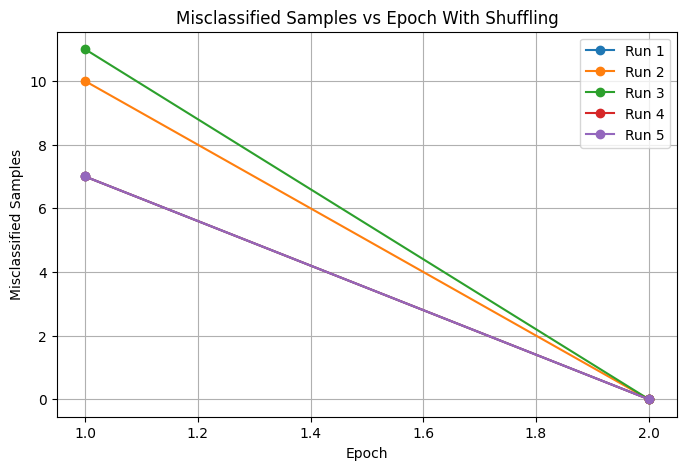

In [ ]:

plt.figure(figsize=(8, 5))

for run in range(5):
    np.random.seed(run)

    _, _, _, errors = perceptron_with_shuffle(
        X_train, y_train,
        learning_rate=0.1,
        max_epochs=1000
    )

    plt.plot(
        range(1, len(errors) + 1),
        errors,
        marker="o",
        label=f"Run {run + 1}"
    )

plt.title("Misclassified Samples vs Epoch With Shuffling")
plt.xlabel("Epoch")
plt.ylabel("Misclassified Samples")
plt.legend()
plt.grid(True)
plt.show()



## Part (k): Effect of Mislabelled Samples on Perceptron Convergence


In [ ]:

np.random.seed(42)

y_noisy = y_train.copy()

num_mislabeled = int(0.10 * len(y_noisy))
mislabeled_indices = np.random.choice(
    len(y_noisy),
    num_mislabeled,
    replace=False
)

y_noisy[mislabeled_indices] = 1 - y_noisy[mislabeled_indices]

print("Total training samples:", len(y_noisy))
print("Mislabelled samples:", num_mislabeled)


Total training samples: 80
Mislabelled samples: 8


In [ ]:

weights_noisy, bias_noisy, epochs_noisy, errors_noisy = perceptron_with_shuffle(
    X_train,
    y_noisy,
    learning_rate=0.1,
    max_epochs=100
)

print("Epochs completed:", epochs_noisy)
print("Misclassified samples per epoch:", errors_noisy)

print("Training accuracy on noisy labels:",
      accuracy_score(
          y_noisy,
          predict_scratch(X_train, weights_noisy, bias_noisy)
      ) * 100, "%")

print("Accuracy against original labels:",
      accuracy_score(
          y_train,
          predict_scratch(X_train, weights_noisy, bias_noisy)
      ) * 100, "%")


Epochs completed: 100
Misclassified samples per epoch: [20, 20, 17, 14, 19, 17, 19, 17, 13, 15, 15, 18, 14, 14, 14, 18, 16, 18, 16, 14, 18, 14, 16, 16, 14, 14, 21, 15, 16, 14, 17, 14, 18, 16, 16, 16, 11, 14, 16, 17, 16, 19, 16, 15, 20, 16, 14, 20, 12, 14, 17, 16, 14, 15, 19, 16, 12, 13, 18, 12, 16, 12, 12, 16, 15, 12, 23, 15, 14, 14, 16, 16, 13, 14, 21, 16, 15, 13, 13, 18, 19, 16, 15, 14, 16, 15, 17, 14, 14, 13, 15, 15, 18, 19, 14, 13, 17, 17, 15, 15]
Training accuracy on noisy labels: 87.5 %
Accuracy against original labels: 97.5 %


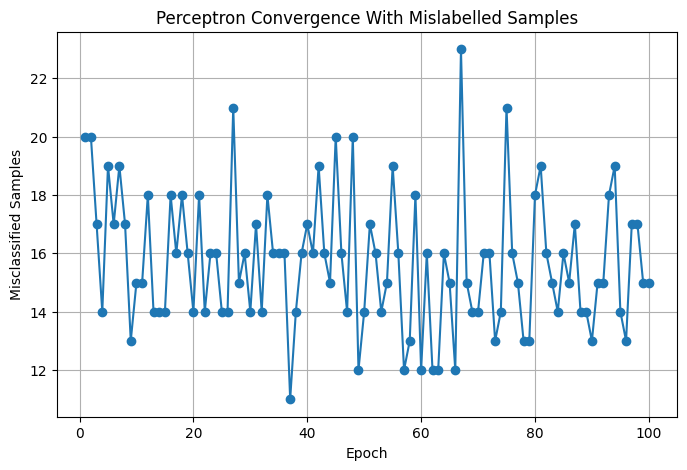

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(errors_noisy) + 1),
    errors_noisy,
    marker="o"
)

plt.title("Perceptron Convergence With Mislabelled Samples")
plt.xlabel("Epoch")
plt.ylabel("Misclassified Samples")
plt.grid(True)
plt.show()
